# Credit Card Transactions Fraud Detection · 01 Data Understanding

# Aim, Objective, and Motivation
- **Aim:** <u>understand</u> the raw data completely before any modeling — what each column means, how clean it is,
  how rare fraud is and how train and test relate in time.
- **Objective:** produce the decisions that the rest of the project depends on: which columns to use,
  which metric to optimise and how to split the data.
- **Motivation:** most fraud-detection mistakes happen *before* the model (leakage, wrong split, wrong metric).

**Dataset:** [Credit Card Transactions Fraud Detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection) (Kaggle, kartik2112),
simulated with [Sparkov](https://github.com/namebrandon/Sparkov_Data_Generation): ~1,000 customers × ~800 merchants, **2019-01-01 → 2020-12-31**.

# Outlines
1. Load data
2. Data dictionary
3. Data health
    - 3.1 Missing values & duplicates
    - 3.2 Descriptive statistics
    - 3.3 Memory usage
4. Target imbalance
5. Train vs test in time
6. Entities: cards and customers
7. Summary & decisions

<!-- objective -->
## Objective

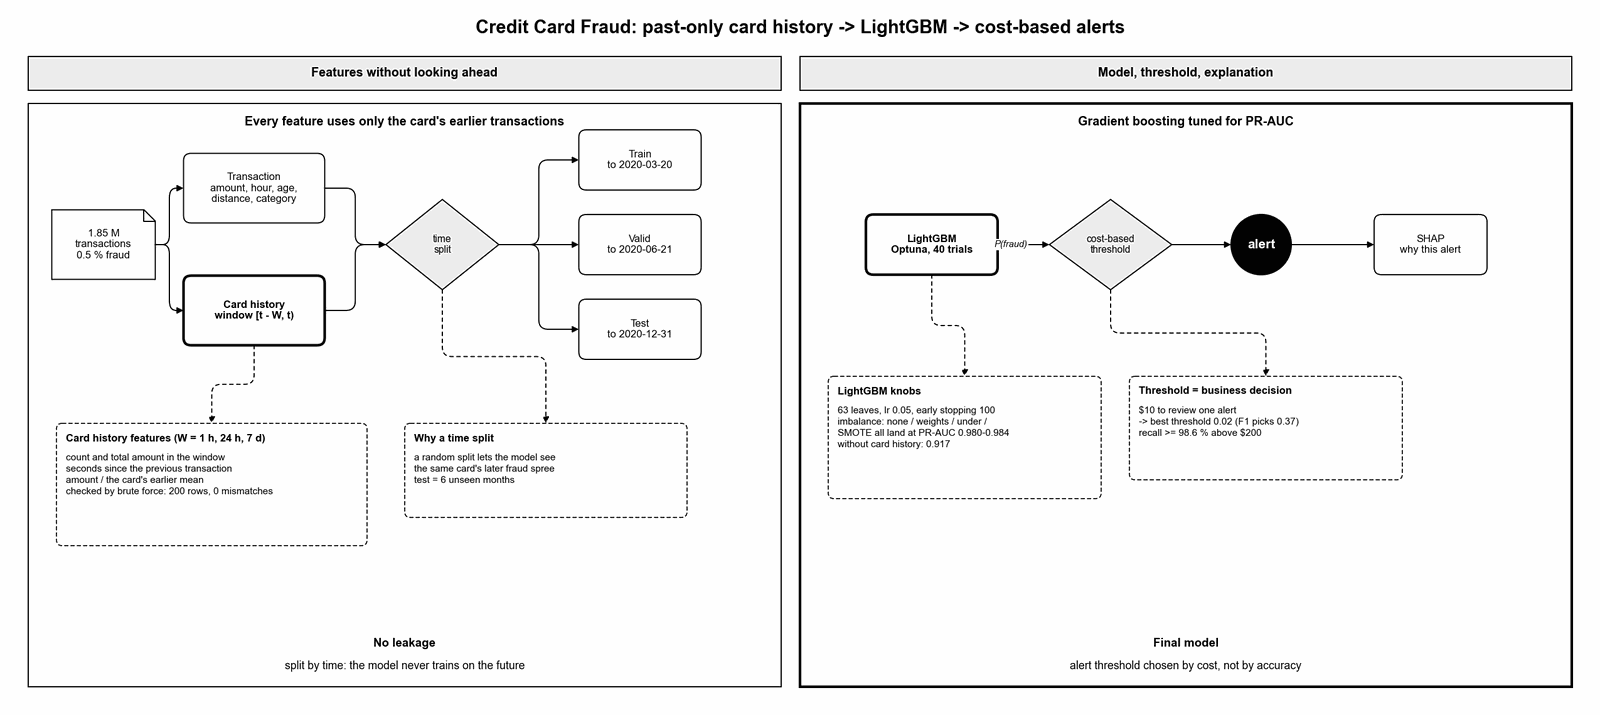

- **Problem** → about 1 in 200 card payments is fraud, and a fraud team can only review so many alerts a day
- **Why this repo** → rank every payment by fraud risk using only what the bank knew *at that moment*, then pick the alert threshold from the cost of a review, not from accuracy
- **Real-world use** → an alert queue: the riskiest payments go to an analyst (or trigger an SMS check) first; the threshold slider trades missed fraud against analyst workload

In [1]:
# ---------------------------------------------------------------- Imports
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src/` importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import COLORS, LABELS, TARGET
from src.data import load_raw
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
SPLITS = ["train", "test"]                 # fraudTrain.csv / fraudTest.csv
NUMERIC_COLS = ["amount", "city_pop", "lat", "long", "merch_lat", "merch_long"]
PERSON_KEY = ["first", "last", "dob"]      # identifies a card holder
MONTH_FREQ = "MS"                          # month-start buckets for the timeline
SPLIT_COLORS = {"train": "#4b5563", "test": "#9ca3af"}

set_style()
pd.set_option("display.max_columns", 50)

# [1/7] Load data
> **Objective:** <u>read</u> both CSV files into DataFrames with correct dtypes (datetimes, categories).

In [2]:
train = load_raw("train")
test = load_raw("test")

In [3]:
print(f"train: {train.shape}")
print(f"test : {test.shape}")
train.head()

train: (1296675, 23)
test : (555719, 23)


,trans_time,card_id,merchant,category,amount,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_id,unix_time,merch_lat,merch_long,is_fraud,source
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,train
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,train
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,train
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,train
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,train


# [2/7] Data dictionary
> **Question:** what does each column mean, and can it be used as a feature?

| Column | Meaning | Use as feature? |
|---|---|---|
| `trans_time` | Timestamp of the transaction | → hour, day of week, card history |
| `card_id` | Credit card number (renamed from `cc_num`) | ✗ identifier, only for grouping |
| `merchant` | Merchant name | ✗ ~700 simulated names |
| `category` | Spending category (14 values) | ✓ |
| `amount` | Transaction amount in USD | ✓ |
| `first`, `last`, `street` | Card holder name / address | ✗ personal identifiers |
| `gender` | Card holder gender | ✓ binary |
| `city`, `state`, `zip` | Card holder location | (!) high cardinality → summarised by `city_pop` / distance |
| `lat`, `long` | Card holder coordinates | → distance to merchant |
| `city_pop` | Population of the holder's city | ✓ (log) |
| `job` | Card holder job (~500 values) | ✗ high cardinality |
| `dob` | Date of birth | → age at transaction |
| `trans_id` | Unique transaction id | ✗ identifier |
| `unix_time` | Same moment as `trans_time` in seconds | ✗ duplicate information |
| `merch_lat`, `merch_long` | Merchant coordinates | → distance to merchant |
| `is_fraud` | **Target** (1 = fraud) | target |

In [4]:
dictionary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "missing": train.isna().sum(),
    "example": train.iloc[0],
})

In [5]:
dictionary

,dtype,n_unique,missing,example
trans_time,datetime64[ns],1274791,0,2019-01-01 00:00:18
card_id,int64,983,0,2703186189652095
merchant,category,693,0,"fraud_Rippin, Kub and Mann"
category,category,14,0,misc_net
amount,float64,52928,0,4.97
first,object,352,0,Jennifer
last,object,481,0,Banks
gender,category,2,0,F
street,object,983,0,561 Perry Cove
city,category,894,0,Moravian Falls


# [3/7] Data health
## 3.1 Missing values & duplicates
> **Question:** is there anything to clean — missing cells, duplicate rows, duplicate ids, impossible amounts?

In [6]:
health = pd.DataFrame({
    "rows": [len(train), len(test)],
    "missing_cells": [train.isna().sum().sum(), test.isna().sum().sum()],
    "duplicate_rows": [train.drop(columns="source").duplicated().sum(),
                       test.drop(columns="source").duplicated().sum()],
    "duplicate_trans_id": [train.trans_id.duplicated().sum(), test.trans_id.duplicated().sum()],
    "non_positive_amount": [(train.amount <= 0).sum(), (test.amount <= 0).sum()],
}, index=SPLITS)

In [7]:
health

,rows,missing_cells,duplicate_rows,duplicate_trans_id,non_positive_amount
train,1296675,0,0,0,0
test,555719,0,0,0,0


**Answer:** nothing to clean — 0 missing values, 0 duplicates, no zero/negative amounts.
The real work is **feature engineering** and **handling the imbalance**.

## 3.2 Descriptive statistics
> **Objective:** <u>check</u> ranges and skewness of the numeric columns.
>
> **Formula (skewness):** $\text{skew} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i-\bar{x}}{s}\right)^3$ — 0 = symmetric, > 1 = highly right-skewed.

In [8]:
desc = train[NUMERIC_COLS].describe().T
desc["skew"] = train[NUMERIC_COLS].skew()

In [9]:
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
amount,1296675.0,70.35,160.32,1.00,9.65,47.52,83.14,28948.90,42.28
city_pop,1296675.0,88824.44,301956.36,23.00,743.00,2456.00,20328.00,2906700.00,5.59
lat,1296675.0,38.54,5.08,20.03,34.62,39.35,41.94,66.69,-0.19
long,1296675.0,-90.23,13.76,-165.67,-96.80,-87.48,-80.16,-67.95,-1.15
merch_lat,1296675.0,38.54,5.11,19.03,34.73,39.37,41.96,67.51,-0.18
merch_long,1296675.0,-90.23,13.77,-166.67,-96.90,-87.44,-80.24,-66.95,-1.15


**Answer:** `amount` is extremely right-skewed (median ≈ \$47, max ≈ \$28,949, skew ≫ 1) and so is
`city_pop` → both will be viewed and used on a **log scale**.

## 3.3 Memory usage
> **Objective:** <u>confirm</u> the full dataset fits comfortably in RAM (text stored as `category` dtype).

In [10]:
memory_mb = pd.Series({name: d.memory_usage(deep=True).sum() / 2**20
                       for name, d in zip(SPLITS, [train, test])}, name="MB")

In [11]:
memory_mb.round(0)

train    572.0
test     245.0
Name: MB, dtype: float64

# [4/7] Target imbalance
> **Question:** how rare is fraud?
>
> **Formula:** $\text{fraud rate} = \frac{\#\,\text{fraud}}{\#\,\text{transactions}}$

In [12]:
imbalance = pd.DataFrame({
    "transactions": [len(train), len(test)],
    "frauds": [train[TARGET].sum(), test[TARGET].sum()],
}, index=SPLITS)
imbalance["fraud_rate_%"] = imbalance.frauds / imbalance.transactions * 100
imbalance["legit_per_fraud"] = imbalance.transactions / imbalance.frauds

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, d) in zip(axes, zip(SPLITS, [train, test])):
    counts = d[TARGET].value_counts().sort_index()
    ax.bar([LABELS[i] for i in counts.index], counts.values, color=[COLORS[i] for i in counts.index])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}\n({v / len(d):.2%})", ha="center", va="bottom")
    ax.set(title=f"{name}: class balance", ylabel="transactions", ylim=(0, counts.max() * 1.2))
savefig(fig, "01_class_balance")
plt.close(fig)  # displayed in its own cell below

In [13]:
imbalance.round(3)

,transactions,frauds,fraud_rate_%,legit_per_fraud
train,1296675,7506,0.579,172.752
test,555719,2145,0.386,259.076


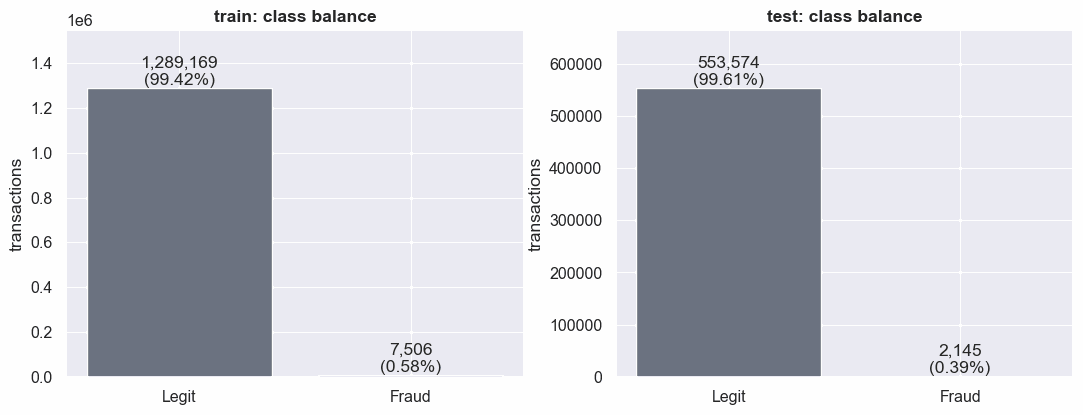

In [14]:
fig

**Answer:** only **~0.5 %** of transactions are fraud (1 in 173 in train, 1 in 259 in test). Consequences:
- **Accuracy is meaningless** — always predicting "legit" already scores 99.4 %.
- We evaluate with **PR-AUC**, **precision / recall** and a **money-based cost**.
- Imbalance strategies (class weights, undersampling, SMOTE) are compared in notebook 04.

# [5/7] Train vs test in time
> **Question:** are `fraudTrain` and `fraudTest` random samples or consecutive periods? Does fraud change over time?
> The answer decides the **validation strategy**.

In [15]:
both = pd.concat([train, test])
periods = both.groupby("source").trans_time.agg(["min", "max"])
monthly = (both.set_index("trans_time")
           .groupby([pd.Grouper(freq=MONTH_FREQ), "source"])[TARGET]
           .agg(["size", "mean"]).reset_index())

fig, ax1 = plt.subplots(figsize=(14, 4.5))
for src, c in SPLIT_COLORS.items():
    m = monthly[monthly.source == src]
    ax1.bar(m.trans_time, m["size"], width=25, color=c, alpha=0.8, label=f"{src} transactions")
ax2 = ax1.twinx()
ax2.plot(monthly.trans_time, monthly["mean"] * 100, color=COLORS[1], marker="o", label="fraud rate %")
ax1.set(ylabel="transactions / month", title="Volume and fraud rate per month")
ax2.set_ylabel("fraud rate (%)")
ax2.grid(False)
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)
savefig(fig, "01_timeline")
plt.close(fig)  # displayed in its own cell below

In [16]:
periods

,min,max
source,,
test,2020-06-21 12:14:25,2020-12-31 23:59:34
train,2019-01-01 00:00:18,2020-06-21 12:13:37


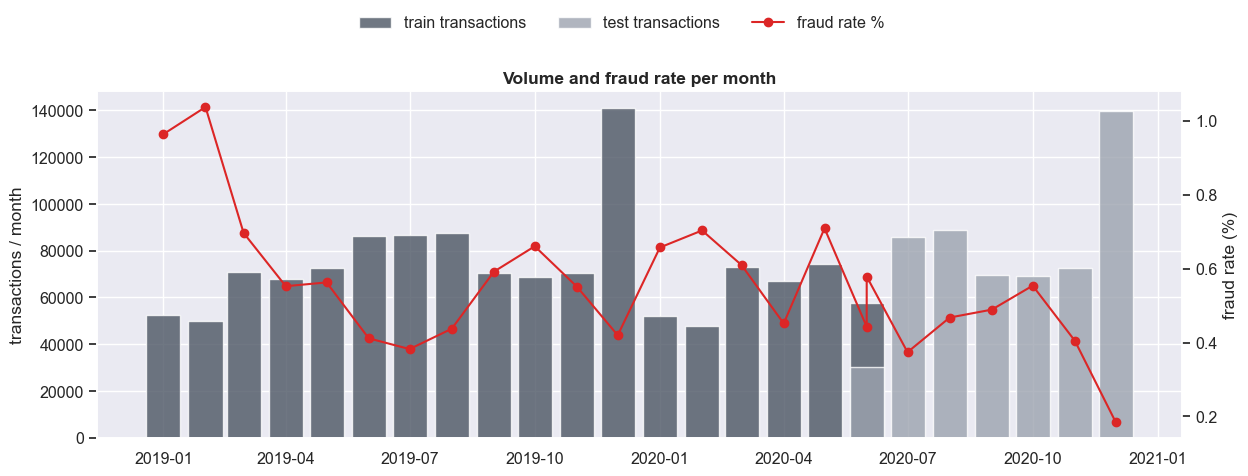

In [17]:
fig

**Answer:**
- `fraudTest` starts **the exact second** `fraudTrain` ends → the official split is a **time split**.
- Volume is seasonal (December peaks) and the fraud rate drifts (train 0.58 % vs test 0.39 %).

→ **Validation strategy:** never shuffle. Train on the past, validate on the most recent part of
`fraudTrain` (from **2020-03-21**), and touch `fraudTest` **once** at the very end.
A random split would leak future patterns into training and give over-optimistic scores.

# [6/7] Entities: cards and customers
> **Question:** how many cards and customers are there, and how is fraud spread across cards?

In [18]:
per_card = both.groupby("card_id", observed=True).agg(n_txn=("trans_id", "size"), n_fraud=(TARGET, "sum"))
cards_per_person = both.groupby(PERSON_KEY, observed=True).card_id.nunique()

In [19]:
print(f"cards                 : {len(per_card):,}")
print(f"cards with ≥ 1 fraud  : {(per_card.n_fraud > 0).sum():,} ({(per_card.n_fraud > 0).mean():.1%})")
print(f"transactions per card : median {per_card.n_txn.median():.0f}, max {per_card.n_txn.max():,}")
print(f"frauds per fraud card : median {per_card.loc[per_card.n_fraud > 0, 'n_fraud'].median():.0f}, "
      f"max {per_card.n_fraud.max()}")
print("cards per person      :", cards_per_person.value_counts().to_dict())

cards                 : 999
cards with ≥ 1 fraud  : 976 (97.7%)
transactions per card : median 1471, max 4,392
frauds per fraud card : median 10, max 19
cards per person      : {1: 999}


**Answer:**
- Every person holds exactly **one card** → "number of cards per person" (used in the old version) carries no signal.
- Almost every card (97.7 %) is hit, typically by **~10 fraudulent transactions** → fraud comes in
  **bursts on a card**. Per-card history features (notebook 03) are the most promising idea.

# [7/7] Summary & decisions
| Finding | Decision |
|---|---|
| Clean data, no missing / duplicates | no cleaning step needed |
| 0.5 % fraud | PR-AUC + cost metrics; compare imbalance strategies |
| Official split is in time, fraud rate drifts | time-based train / valid / test |
| Fraud happens in bursts per card | build leak-free card history features |
| Identifiers & high-cardinality text | drop, or summarise (distance, city_pop) |